In [1]:
import numpy as np
import scipy
import seaborn as sb
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['pdf.fonttype'] = 42
from matplotlib.colors import ListedColormap
import drift_functions as df
import torch
from torch import nn


In [6]:
np.random.seed(22)

Nx= 15 
Ny = 12 
Nz = 1
P = 8 
h_min = 0
h_max = 5
err_thresh = 0.01

eta_clip = False
num_runs = 500000


U = np.random.normal(0, 0.5, (Ny, Nx))
U_T = np.random.normal(0, 0.5, (Ny, Nx))
W =  np.random.normal(0, 10, (1,Ny))
W_T = np.copy(W)


X = np.random.normal(0,1,(Nx, P))
Z = (W@np.clip(U_T@X, h_min, h_max))



input_data = torch.Tensor(X.T) 
target_data = torch.Tensor(Z.T)
model = df.MLP(Nx, Ny, Nz,  U, W)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


all_errors = []

found_sol = False
successfully_found = False
while found_sol == False:
    output = model(input_data)
    loss = criterion(output, target_data)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    all_errors.append(loss.item())
    if err_thresh>abs(all_errors[-1]):
        found_sol = True
        successfully_found = True

    elif len(all_errors)>10 and np.isclose(all_errors[-10], all_errors[-1]):
        found_sol = True

if successfully_found == True:
    U_found_gd = (model.l1.weight.detach()).numpy()
    lr = 0.1
    Unormmax = 350
    print('doing drift')
    U_drift, num_saturated, num_inactive, U_sum_all, W_new, W_sum_all, U_all, error_all, U_diff, Y_diff,redos, all_problems = df.representational_drift_fixed_Unorm(U_found_gd, X,W, num_runs, h_min, h_max, Unormmax*np.ones(Ny), np.sum(W**2), False, lr=lr)
    ##U_drift, num_saturated, num_inactive, U_sum_all, W_new, W_sum_all, U_all, error_all, U_diff, Y_diff,redos, all_problems = representational_drift_fixed_Unorm(U_found_gd, X,W, num_runs, h_min, h_max, Unormmax*np.ones(Ny), np.sum(W**2), False, eta_clip)

doing drift
Z given [[  9.87287111  47.04932404  21.33648809 -12.95810887  12.74010279
    3.36091194 -11.62844341 -41.12883704]]
0 [4.04771045 4.3080617  4.47692896 2.77099463 4.32076933 3.74389223
 4.87962791 4.01710455 3.39492618 1.83315263 6.05578761 2.98406649] [[  9.87287111  47.04932404  21.33648809 -12.95810887  12.74010279
    3.36091194 -11.62844341 -41.12883704]]
100 [3.6500091  4.91080392 4.77868695 3.37657    5.03346732 3.79222895
 6.22201868 3.8222346  3.06722611 1.68084505 6.52804382 3.40192791] [[  9.87287111  47.04932404  21.33648809 -12.95810887  12.74010279
    3.36091194 -11.62844341 -41.12883704]]
200 [3.91257523 4.97652108 4.73032919 2.98811465 4.75686667 4.03100624
 5.22640372 3.89007182 3.06919991 2.14256224 6.36972051 4.26495999] [[  9.87287111  47.04932404  21.33648809 -12.95810887  12.74010279
    3.36091194 -11.62844341 -41.12883704]]
300 [3.80149244 5.27035542 5.45752522 3.20637194 4.96961311 4.52329304
 5.32854973 4.13659333 2.91163482 1.95697514 5.8808230

In [7]:
U_before = U_found_gd.copy()
U_after = U_drift.copy()

Y_before = np.clip(U_before@X, h_min, h_max)
Y_after = np.clip(U_after@X, h_min, h_max)

Z_before = W@Y_before
Z_after = W@Y_after

Y_all = np.zeros((np.shape(U_all)[0], Ny,P))
for t in range(len(U_all)):
    Y_all[t] = np.clip(U_all[t]@X, h_min, h_max)

# Fig 5 A, B, C

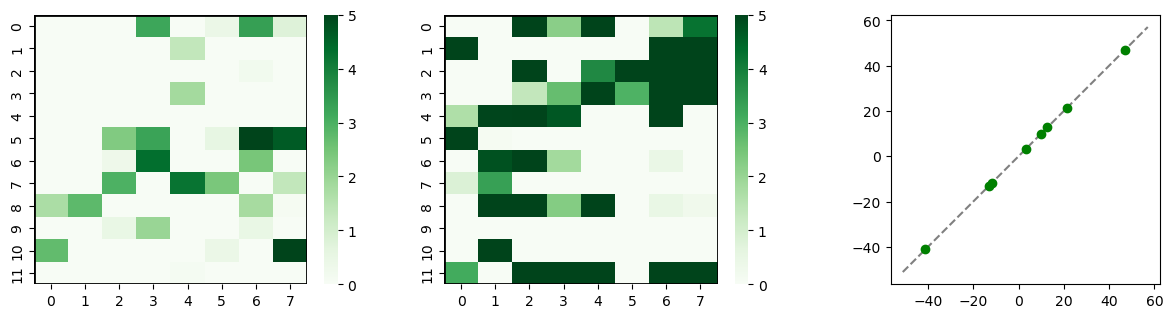

In [8]:
fig, axs = plt.subplots(1,3,figsize = (15,3.5))

yvmin = np.minimum(np.min(Y_before), np.min(Y_after))
yvmax = np.maximum(np.max(Y_before), np.max(Y_after))

sb.heatmap(Y_before, ax = axs[0],rasterized = True,vmin = yvmin, vmax = yvmax, cmap = 'Greens')
sb.heatmap(Y_after, ax = axs[1], rasterized = True,vmin = yvmin, vmax = yvmax, cmap = 'Greens')

plot_equal = np.linspace(np.min(Z_before)-10, np.max(Z_before)+10,100)
axs[2].plot(plot_equal, plot_equal, linestyle = '--', color = 'gray',rasterized = False)
axs[2].plot(Z_before, Z_after,'o', color = 'green')
axs[2].set_aspect('equal')

for i in range(0,2):
    
    yshape = Y_before.shape[0]
    xshape = Y_before.shape[1]
    axs[i].axhline(y=0, color='k',linewidth=2)
    axs[i].axhline(y=yshape, color='k',linewidth=2)
    axs[i].axvline(x=0, color='k',linewidth=2)
    axs[i].axvline(x=xshape, color='k',linewidth=2)

# Fig 5 D

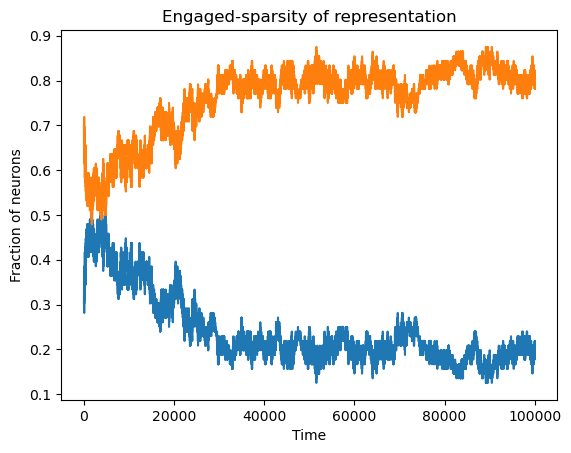

In [9]:
num_saturated = np.array(num_saturated)
num_inactive = np.array(num_inactive)
frac_disengaged = (num_saturated + num_inactive)/(Ny*P)
frac_engaged = 1-frac_disengaged
plt.plot(frac_engaged, label = 'engaged')
plt.plot(frac_disengaged, label = 'disengaged')
plt.title('Engaged-sparsity of representation')
plt.xlabel('Time')
plt.ylabel('Fraction of neurons')
plt.show()

# Fig 5 E

Text(181.94444444444446, 0.5, 'Y neuron')

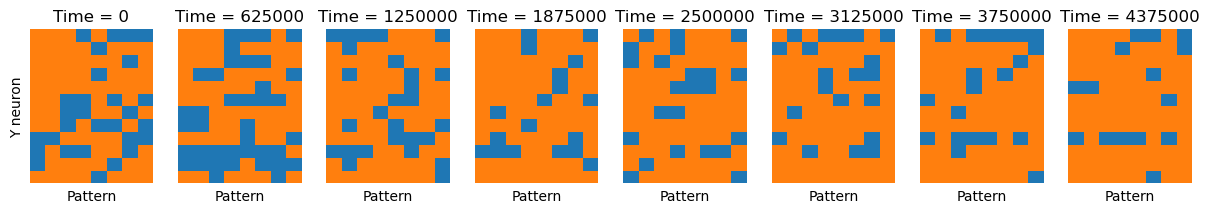

In [10]:
num_figures = 8
h_prime = 10**-12
sat_alpha = h_max
each_mul = int(len(Y_all)/num_figures)

fig, axs = plt.subplots(1,num_figures, figsize = (15,2))



for figcount in range(0, num_figures):
    t = figcount*each_mul
    eng_dis = np.zeros_like(Y_all[t])
    eng_dis[np.where(Y_all[t]<h_prime)] = 1
    eng_dis[np.where(Y_all[t]>sat_alpha-h_prime)] = 1


    cmap_bo = ['#1f77b4', '#ff7f0e']
    ##sb.palplot(sb.color_palette(cmap_bo))
    my_colors = ListedColormap(sb.color_palette(cmap_bo))
    sb.heatmap(eng_dis, cmap = my_colors, cbar = False, ax = axs[figcount], rasterized = True)
    axs[figcount].set_xticks([])
    axs[figcount].set_yticks([])
    axs[figcount].set_xlabel('Pattern')
    axs[figcount].set_title('Time = ' + str(t*50))  ## record every 50 steps, sigma 0.01
axs[0].set_ylabel('Y neuron')

# Fig 5 F

([[-1.5849089583398472],
  [-0.3405132841301113],
  [8.142824665757027],
  [5.277834520775655]],
 68.81752994348693,
 27.971486525360255)

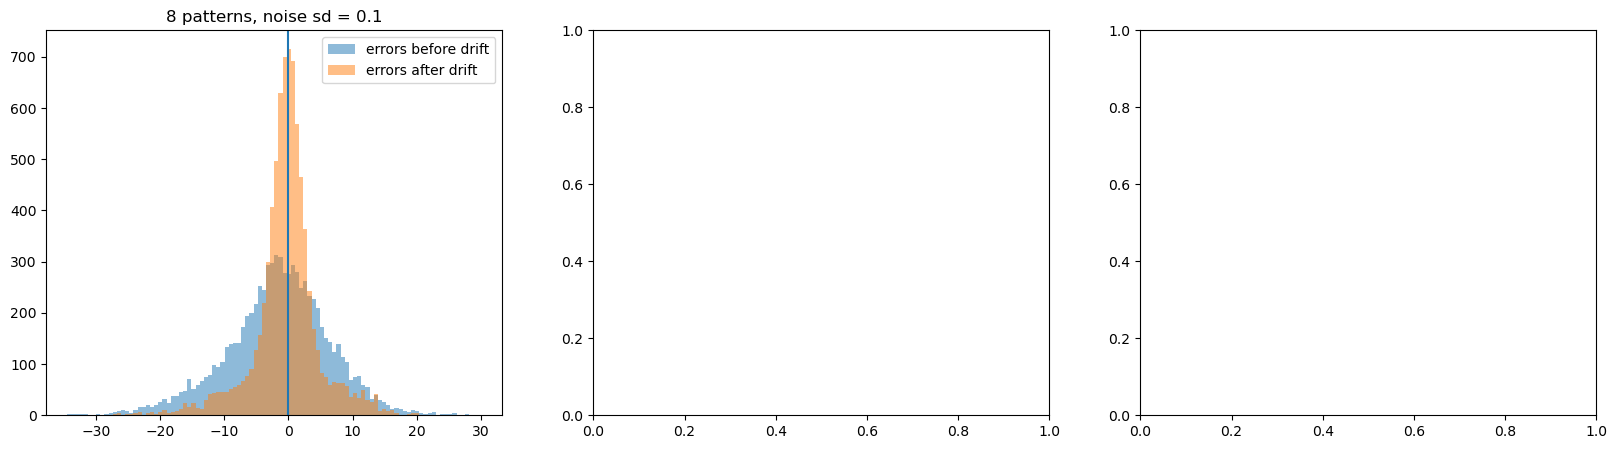

In [11]:
df.robustness_plotter(U_before, U_after, X, h_min, h_max,W, W, 'U')

# Fig 6 B,C

<Axes: >

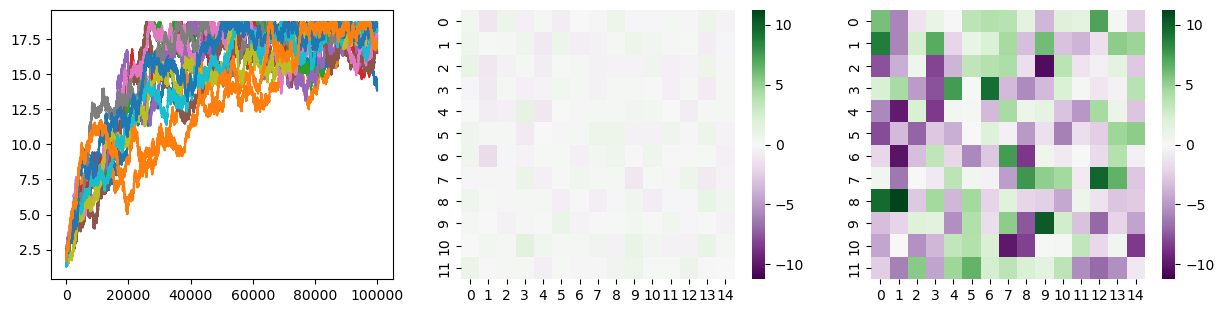

In [12]:
fig, axs = plt.subplots(1,3,figsize = (15,3.5))
axs[0].plot(np.sqrt(U_sum_all))
yvmin = np.minimum(np.min(U_before), np.min(U_after))
yvmax = np.maximum(np.max(U_before), np.max(U_after))
uminmax = np.maximum(abs(yvmin), yvmax)
sb.heatmap(U_before, ax = axs[1],rasterized = True,vmin = -uminmax, vmax = uminmax, cmap = 'PRGn')
sb.heatmap(U_after, ax = axs[2], rasterized = True,vmin = -uminmax, vmax = uminmax, cmap = 'PRGn')
##plt.savefig('../../FIGURES/weight_norm_bound_sqrt(sum U**2).pdf', format='pdf', dpi=500)
##plt.savefig()